# Dictionary 276 on the third LeiData recording

Dictionary 276 (`randomized_builder_SOCAL_H_76_230427_014845.x`) has 83 atoms learned on the GPL whitened spectrogram of `SOCAL_H_76_230427_014845.x.wav`, the third LeiData `.x.wav`. Each atom is correlated with that same spectrogram, 30 windows joined in time.

At spectrogram column `t` the stored value is the amplitude matching pursuit uses:

`alpha(t) = <S[:, t:t+W], A> / ||A||^2`

`S` is the whitened spectrogram, `A` is the atom, and `W` is the atom width in time bins. This is the sum of a valid correlation on each frequency row. Columns where the atom would run past the end of the recording are NaN.

The array is `scores` in `/home/yfreund/whale_processing/result/LeiData/dict276_014845_convolution/scores.npz`, shape `(83, 18270)`. Row `i` is atom `template_i`. Column `t` starts `t * 0.12288` seconds into the recording.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "analysis" / "GPL_Python" / "gpl_signal.py").is_file():
        if str(candidate) not in sys.path:
            sys.path.insert(0, str(candidate))
        break

from analysis.GPL_Python.gpl_outputs import display_from_spwhiten

OUT = Path("/home/yfreund/whale_processing/result/LeiData/dict276_014845_convolution")
ATOM_DIR = Path(
    "/home/yfreund/whale_processing/result/reviewed_rebuilds/"
    "SOCAL_H_76_230427_014845.x/randomized_builder_20261101T235819498430"
)

bundle = np.load(OUT / "scores.npz")
scores = bundle["scores"]
widths = bundle["width"]
sec_per_bin = float(bundle["sec_per_bin"])
start_freq = float(bundle["start_freq"])
end_freq = float(bundle["end_freq"])
time_min = np.arange(scores.shape[1]) * sec_per_bin / 60.0
atoms = [np.load(ATOM_DIR / f"template_{i:03d}.npy") for i in range(scores.shape[0])]

print(f"scores {scores.shape}  bin {sec_per_bin:.5f} s  duration {scores.shape[1] * sec_per_bin / 60:.2f} min")
for i, width in enumerate(widths):
    row = scores[i]
    k = int(np.nanargmax(np.abs(row)))
    print(
        f"atom {i}  width {int(width)} bins ({int(width) * sec_per_bin:.2f} s)  "
        f"peak {row[k]:.4f} at {time_min[k]:.2f} min"
    )


scores (83, 18270)  bin 0.12288 s  duration 37.42 min
atom 0  width 20 bins (2.46 s)  peak 5.0403 at 9.46 min
atom 1  width 24 bins (2.95 s)  peak 7.2823 at 0.01 min
atom 2  width 26 bins (3.19 s)  peak 4.3150 at 12.73 min
atom 3  width 21 bins (2.58 s)  peak 4.4462 at 6.54 min
atom 4  width 36 bins (4.42 s)  peak 3.1541 at 10.05 min
atom 5  width 29 bins (3.56 s)  peak 3.9091 at 17.00 min
atom 6  width 25 bins (3.07 s)  peak 4.3648 at 0.00 min
atom 7  width 26 bins (3.19 s)  peak 5.8085 at 0.00 min
atom 8  width 47 bins (5.78 s)  peak 3.1384 at 34.35 min
atom 9  width 47 bins (5.78 s)  peak -7.7906 at 0.38 min
atom 10  width 20 bins (2.46 s)  peak 13.5238 at 0.15 min
atom 11  width 33 bins (4.06 s)  peak 6.4160 at 0.37 min
atom 12  width 20 bins (2.46 s)  peak 7.5678 at 0.66 min
atom 13  width 23 bins (2.83 s)  peak -6.1052 at 34.37 min
atom 14  width 27 bins (3.32 s)  peak -7.9069 at 0.00 min
atom 15  width 25 bins (3.07 s)  peak 9.2121 at 37.26 min
atom 16  width 30 bins (3.69 s)  p

## Atoms

Each image is the cube root of the absolute atom, the same display transform as the GPL spectrogram. Time runs left to right and frequency upward, from 10 Hz to 10 kHz. The number on each panel is the atom index.

/tmp/ipykernel_1219729/1330768828.py:21: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


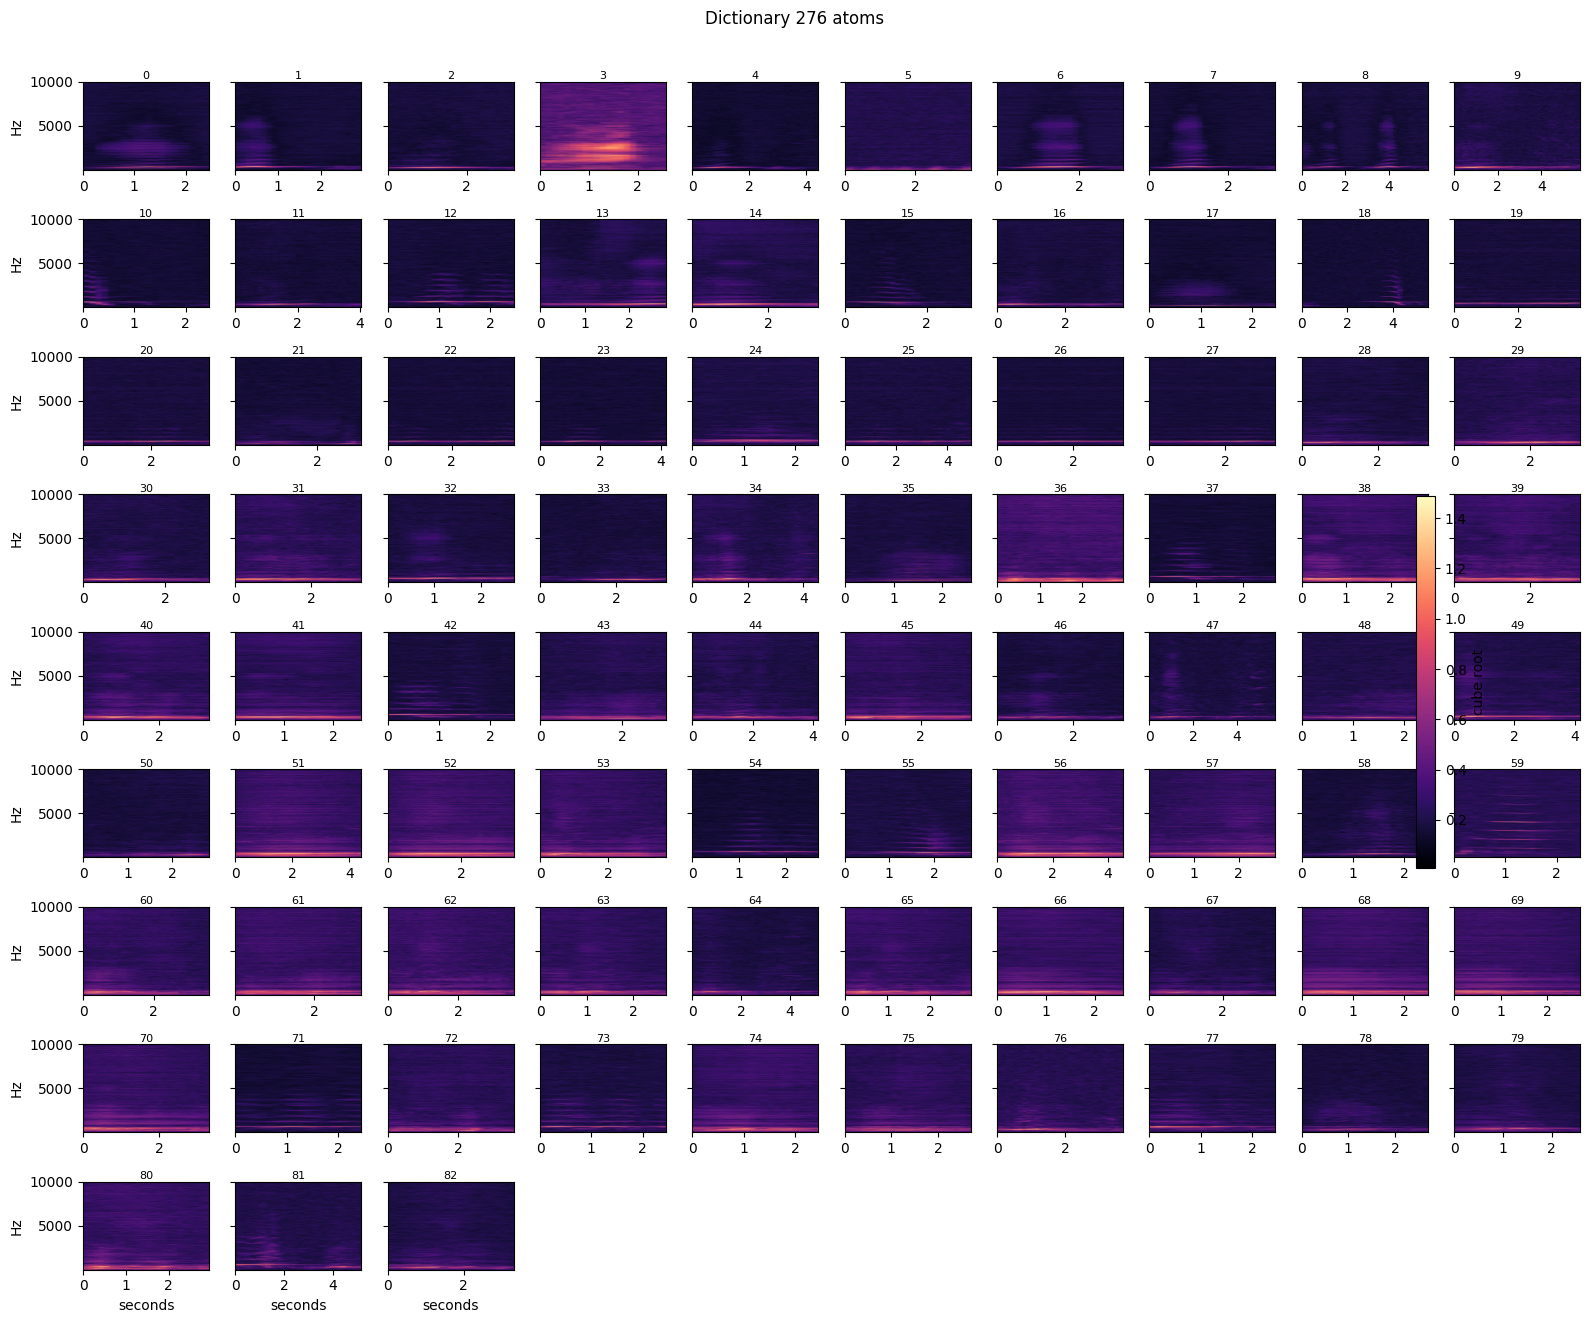

In [2]:
ncols = 10
nrows = int(np.ceil(len(atoms) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 1.45 * nrows), sharey=True)
axes = np.atleast_2d(axes)
for i, atom in enumerate(atoms):
    r, c = divmod(i, ncols)
    ax = axes[r, c]
    shown = display_from_spwhiten(atom)
    extent = [0, atom.shape[1] * sec_per_bin, start_freq, end_freq]
    im = ax.imshow(shown, origin="lower", aspect="auto", cmap="magma", extent=extent)
    ax.set_title(str(i), fontsize=8, pad=2)
    if c == 0:
        ax.set_ylabel("Hz")
    if r == nrows - 1:
        ax.set_xlabel("seconds")
for j in range(len(atoms), nrows * ncols):
    r, c = divmod(j, ncols)
    axes[r, c].axis("off")
fig.colorbar(im, ax=axes, fraction=0.015, pad=0.01, label="cube root")
fig.suptitle("Dictionary 276 atoms", y=1.01)
fig.tight_layout()
plt.show()


## Correlation from 9 to 11 minutes

`scores[i, t]` is the amplitude of atom `i` starting at time bin `t`. Each row is one atom, and every row uses the same clock time, centered at 10 minutes.

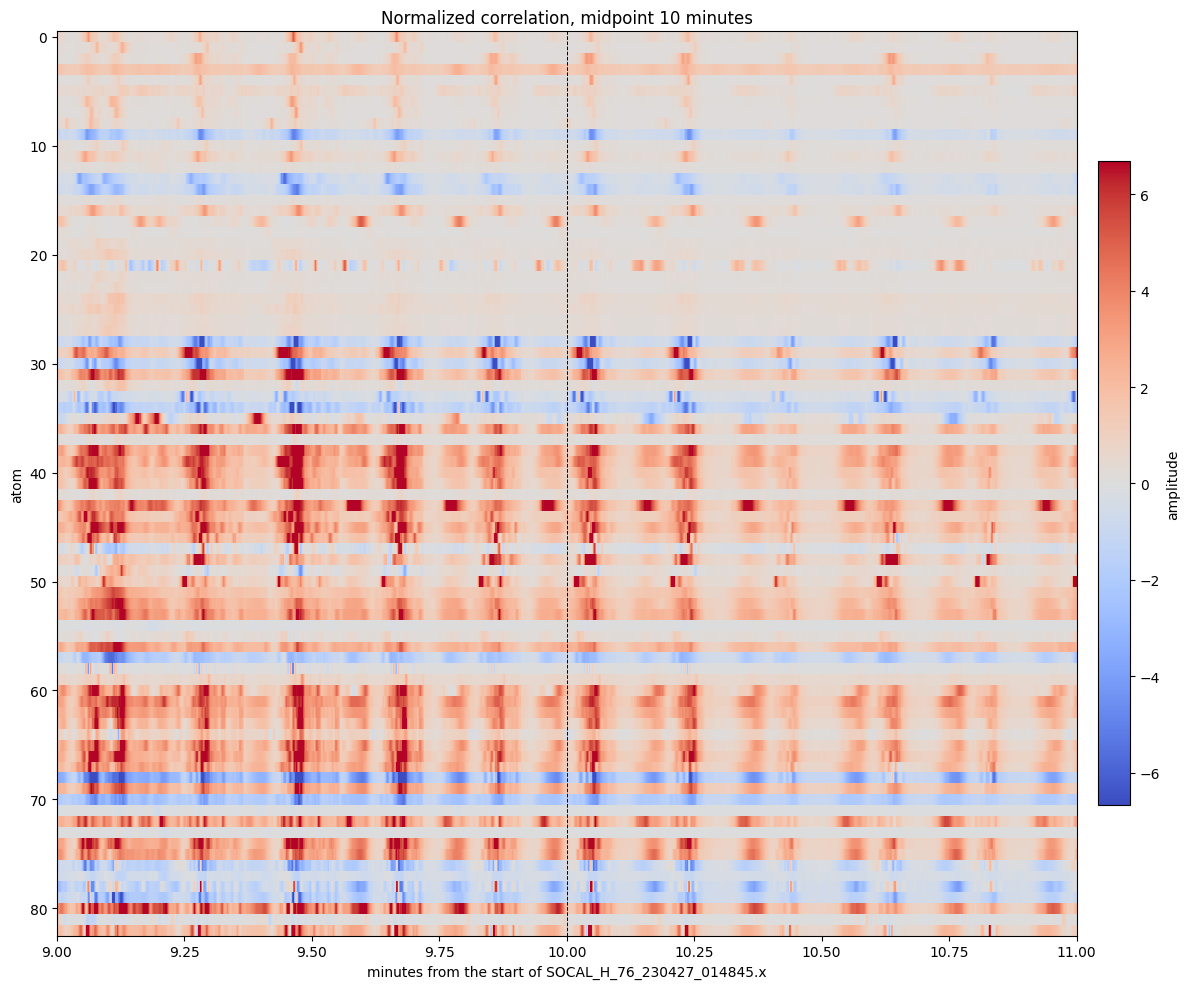

In [3]:
center_min = 10.0
half_min = 1.0
t_s = np.arange(scores.shape[1]) * sec_per_bin
mask = (t_s >= (center_min - half_min) * 60.0) & (t_s <= (center_min + half_min) * 60.0)
window = scores[:, mask]
limit = float(np.nanpercentile(np.abs(window), 99))
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(
    window,
    aspect="auto",
    cmap="coolwarm",
    vmin=-limit,
    vmax=limit,
    interpolation="nearest",
    extent=[center_min - half_min, center_min + half_min, scores.shape[0] - 0.5, -0.5],
)
ax.axvline(center_min, color="k", lw=0.7, ls="--")
ax.set_xlabel("minutes from the start of SOCAL_H_76_230427_014845.x")
ax.set_ylabel("atom")
ax.set_title("Normalized correlation, midpoint 10 minutes")
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, label="amplitude")
fig.tight_layout()
plt.show()


## Motif responses from 9 to 11 minutes

Each row is one motif score over the same two minutes, centered at 10.00.

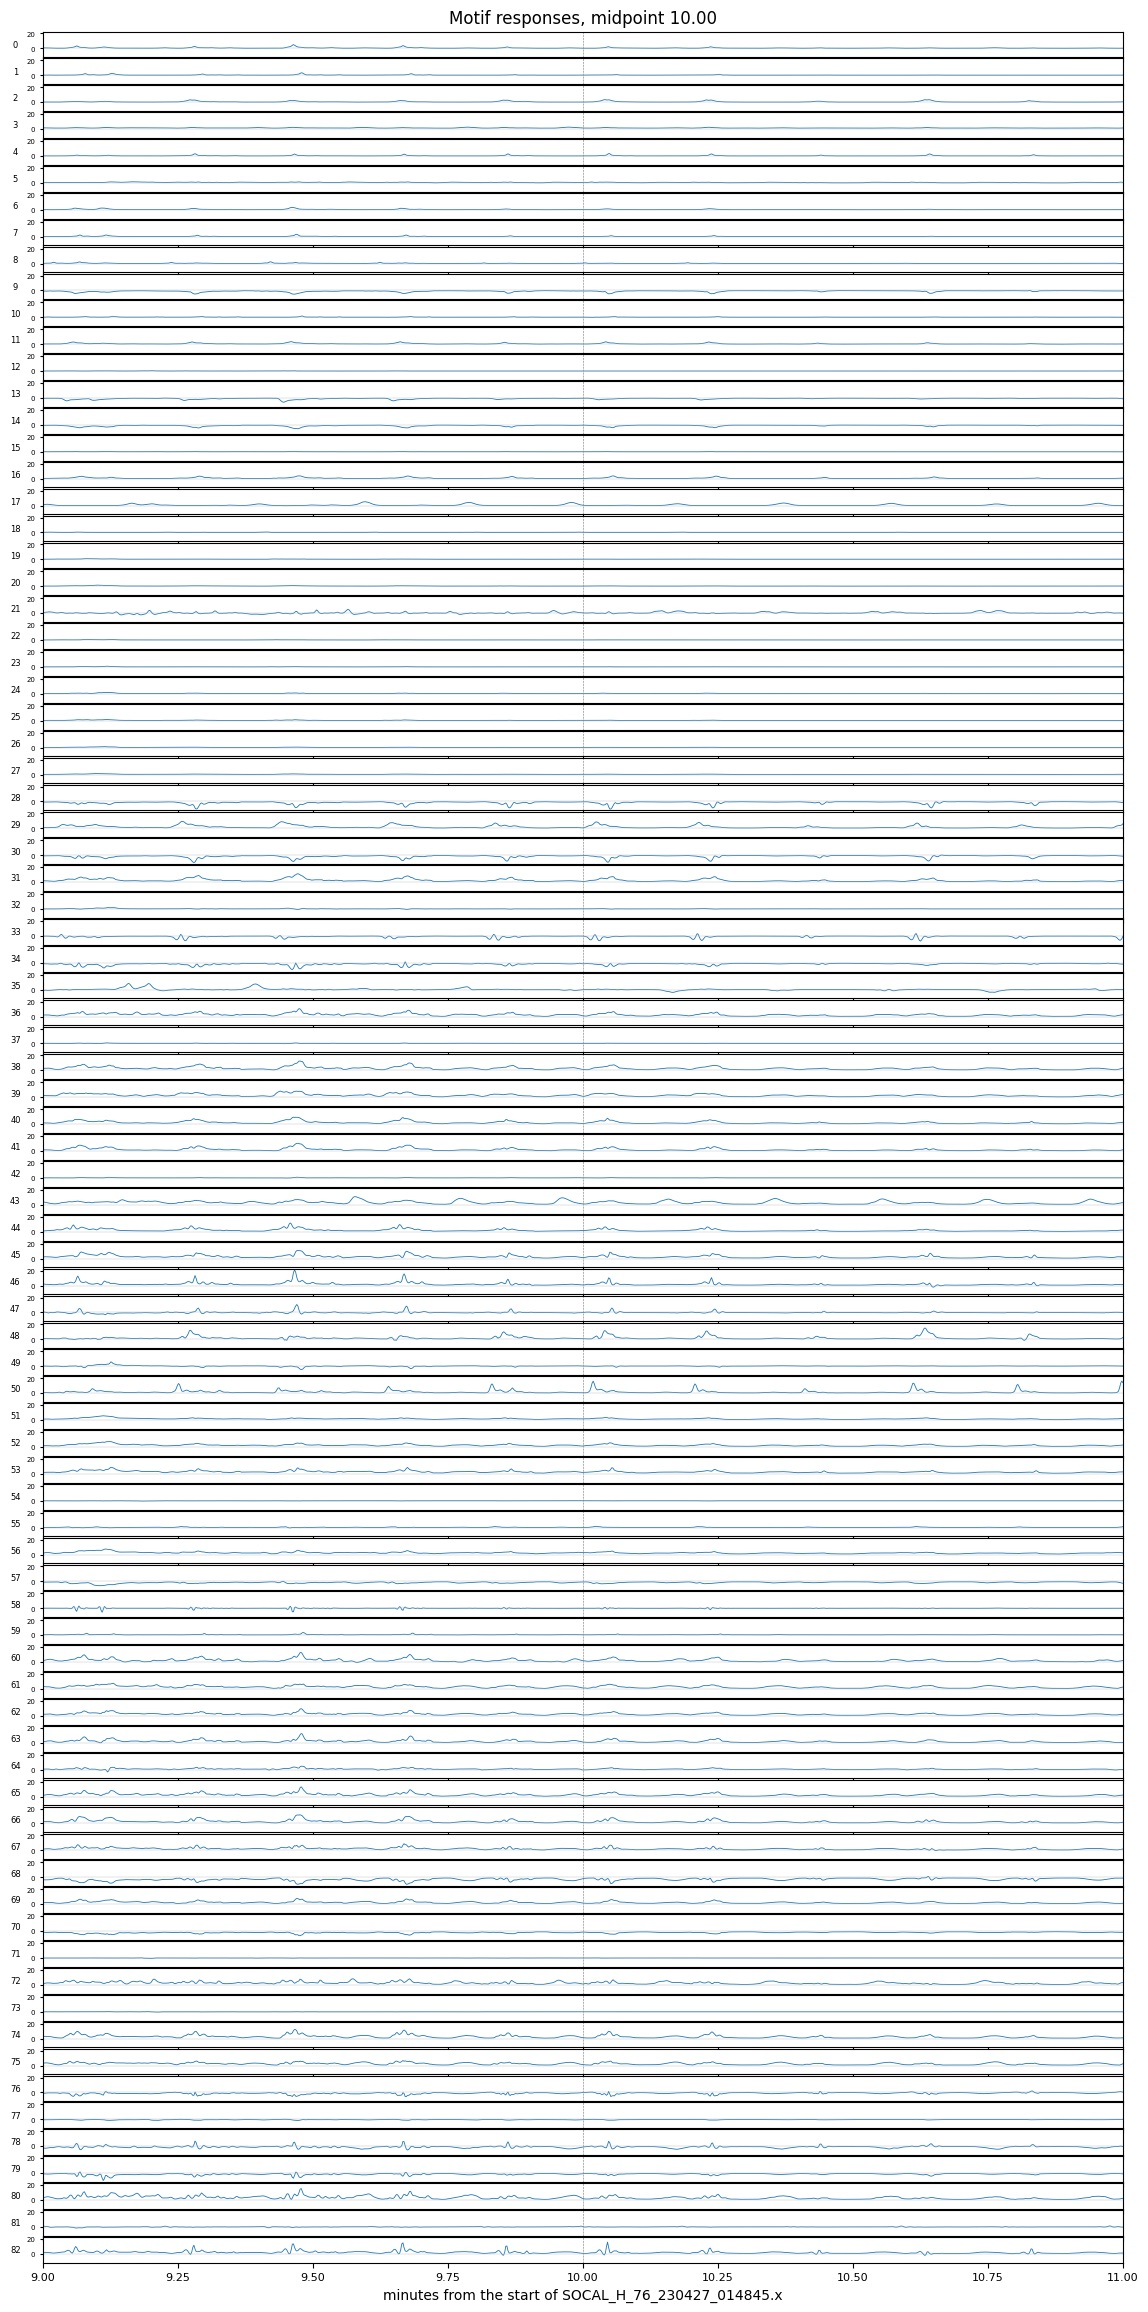

In [4]:
center_min = 10.0
half_min = 1.0
t_s = np.arange(scores.shape[1]) * sec_per_bin
mask = (t_s >= (center_min - half_min) * 60.0) & (t_s <= (center_min + half_min) * 60.0)
t_min = t_s[mask] / 60.0
n = scores.shape[0]
fig, axes = plt.subplots(n, 1, figsize=(12, 0.28 * n), sharex=True, sharey=True)
for i, ax in enumerate(np.atleast_1d(axes)):
    ax.plot(t_min, scores[i, mask], color="C0", lw=0.6)
    ax.axvline(center_min, color="0.45", lw=0.4, ls="--")
    ax.axhline(0, color="0.75", lw=0.3)
    ax.set_ylabel(str(i), fontsize=6, rotation=0, labelpad=8, va="center")
    ax.tick_params(axis="y", labelsize=5, length=2)
    ax.tick_params(axis="x", labelsize=8)
axes[-1].set_xlim(center_min - half_min, center_min + half_min)
axes[-1].set_xlabel("minutes from the start of SOCAL_H_76_230427_014845.x")
axes[0].set_title("Motif responses, midpoint 10.00")
fig.subplots_adjust(hspace=0.05, left=0.08, right=0.98, top=0.98, bottom=0.02)
plt.show()


## Spectrogram and matching-pursuit detections, 19 to 21 minutes

The spectrogram is the cube root of the whitened STFT from 0 to 500 Hz. The stored spectrogram begins at 12 Hz. Each bar is one kept placement of dictionary 276: atom on the vertical axis, time span equal to that atom's width, color equal to the placement amplitude.

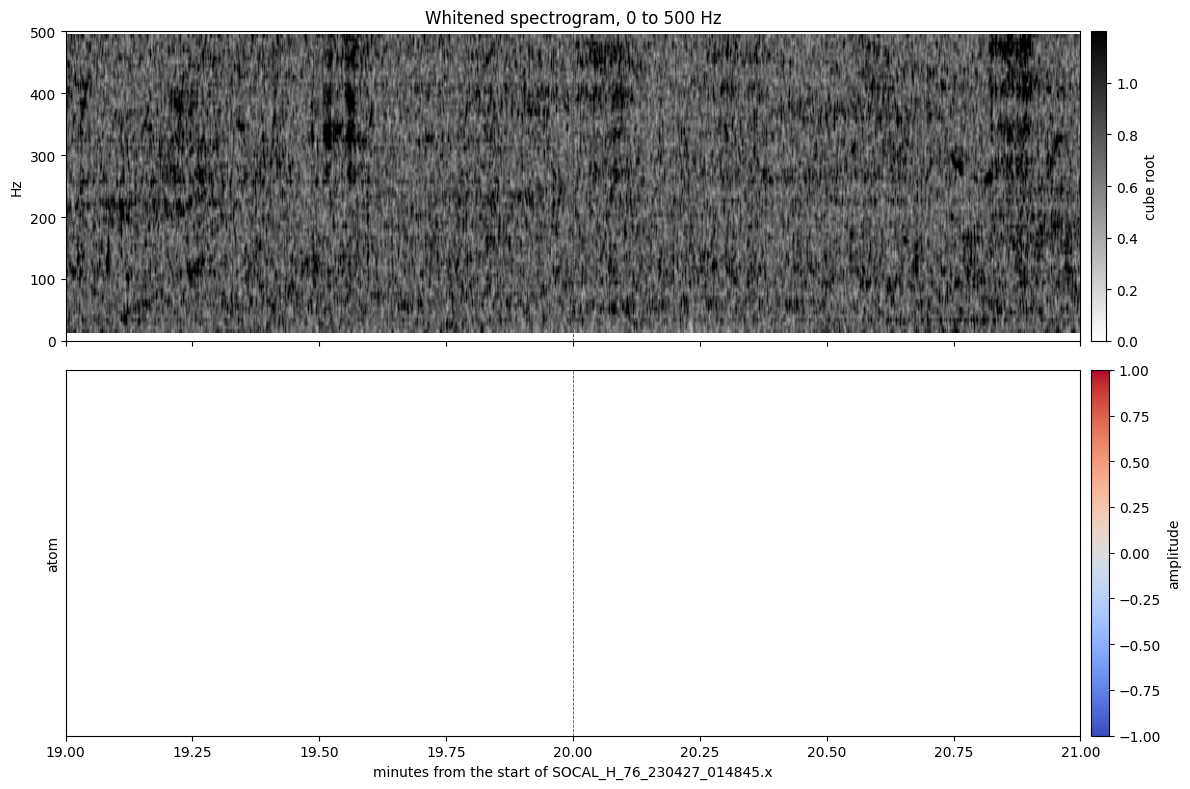

0 detections of 0 atoms in this window


In [5]:
import sqlite3

from analysis.dict_learning.code.io import discover_windows

NPY = Path(
    "/home/yfreund/whale_processing/result/LeiData/"
    "SOCAL_H_76_230427_014845.x.gpl/output/spectrogram_npy"
)
windows = discover_windows(NPY)
windows.sort(key=lambda w: (w.start_sample, w.window_id))
offset = {}
col = 0
for window in windows:
    offset[window.window_id] = col
    col += int(window.data.shape[1])
sec_per_bin = float(windows[0].overlap) / float(windows[0].sample_freq)
start_freq = float(windows[0].start_freq)
end_freq = float(windows[0].end_freq)

lo_s, hi_s = 19 * 60.0, 21 * 60.0
lo = int(np.floor(lo_s / sec_per_bin))
hi = int(np.ceil(hi_s / sec_per_bin))
parts = []
for window in windows:
    a = offset[window.window_id]
    b = a + int(window.data.shape[1])
    if b <= lo or a >= hi:
        continue
    sl = window.data[:, max(0, lo - a) : min(window.data.shape[1], hi - a)]
    parts.append(np.asarray(sl, dtype=np.float64))
chunk = np.concatenate(parts, axis=1)
freq_axis = np.linspace(0.0, float(windows[0].sample_freq) / 2.0, int(windows[0].fftl) // 2)
i0 = int(np.argmin(np.abs(freq_axis - start_freq)))
freqs = freq_axis[i0 : i0 + chunk.shape[0]]
band = np.flatnonzero(freqs <= 500.0)
chunk = chunk[int(band[0]) : int(band[-1]) + 1]
f_lo = float(freqs[int(band[0])])
f_hi = float(freqs[int(band[-1])])
shown = display_from_spwhiten(chunk)
t_left = lo * sec_per_bin / 60.0
t_right = (lo + chunk.shape[1]) * sec_per_bin / 60.0

conn = sqlite3.connect("/home/yfreund/whale_processing/result/dict_learning_catalog.sqlite")
detections = conn.execute(
    """
    SELECT m.t_start, m.amplitude, t.template_id, t.width, m.window_id
    FROM matchings m
    JOIN templates t ON t.template_pk = m.template_pk
    WHERE m.dictionary_id = 276
    """
).fetchall()
conn.close()

kept = []
for t_start, amplitude, template_id, width, window_id in detections:
    if window_id not in offset:
        continue
    g0 = offset[window_id] + int(t_start)
    g1 = g0 + int(width)
    start_min = g0 * sec_per_bin / 60.0
    end_min = g1 * sec_per_bin / 60.0
    if end_min < 19.0 or start_min > 21.0:
        continue
    kept.append((int(template_id), start_min, end_min, float(amplitude)))

atoms = sorted({row[0] for row in kept})
y_of = {atom: i for i, atom in enumerate(atoms)}
limit = max((abs(row[3]) for row in kept), default=1.0)
norm = plt.Normalize(vmin=-limit, vmax=limit)
cmap = plt.cm.coolwarm

fig, (ax_spec, ax_det) = plt.subplots(
    2, 1, figsize=(12, 8), sharex=True, gridspec_kw={"height_ratios": [2.2, 2.6]}
)
contrast_hi = float(np.percentile(shown, 98))
im = ax_spec.imshow(
    shown,
    origin="lower",
    aspect="auto",
    cmap="gray_r",
    vmin=0.0,
    vmax=contrast_hi,
    extent=[t_left, t_right, f_lo, f_hi],
)
ax_spec.set_ylim(0.0, 500.0)
ax_spec.axvline(20.0, color="0.25", lw=0.6, ls="--")
ax_spec.set_ylabel("Hz")
ax_spec.set_title("Whitened spectrogram, 0 to 500 Hz")
fig.colorbar(im, ax=ax_spec, fraction=0.02, pad=0.01, label="cube root")

for atom, start_min, end_min, amplitude in kept:
    ax_det.barh(
        y_of[atom],
        max(0.0, min(21.0, end_min) - max(19.0, start_min)),
        left=max(19.0, start_min),
        height=0.7,
        color=cmap(norm(amplitude)),
        align="center",
    )
ax_det.axvline(20.0, color="0.3", lw=0.6, ls="--")
ax_det.set_yticks(range(len(atoms)))
ax_det.set_yticklabels([str(atom) for atom in atoms], fontsize=7)
ax_det.set_ylabel("atom")
ax_det.set_xlabel("minutes from the start of SOCAL_H_76_230427_014845.x")
ax_det.set_xlim(19.0, 21.0)
ax_det.set_ylim(-0.8, max(len(atoms) - 0.2, 0.8))
fig.colorbar(
    plt.cm.ScalarMappable(norm=norm, cmap=cmap),
    ax=ax_det,
    fraction=0.02,
    pad=0.01,
    label="amplitude",
)
fig.tight_layout()
plt.show()
print(f"{len(kept)} detections of {len(atoms)} atoms in this window")


## Dictionary evaluation

Coverage, over-coverage, and the median of each motif's filtered specificity distribution for dictionary 276 on the default wave file. `k` is the standard deviation of the smoothing Gaussian, half of each motif width, and `m` is 2.

In [6]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "analysis" / "evaluation" / "core.py").is_file():
        if str(candidate) not in sys.path:
            sys.path.insert(0, str(candidate))
        break

from analysis.evaluation import evaluate_dictionary

result = evaluate_dictionary()
print(result["wav"])
print(f"coverage {result['coverage']:.4f}  ({result['n_bins_covered']} / {result['n_bins_total']} columns)")
print(f"over-coverage {result['over_coverage']:.4f}  (placed length {result['placed_length']})")
print(f"m {result['m']}")
medians = result["specificity_median"]
shifts = result["k"]
distributions = result["specificity"]
for motif_id in sorted(medians):
    print(
        f"motif {motif_id:3d}  k={shifts[motif_id]:.0f}  "
        f"median={medians[motif_id]:.4f}  n={len(distributions[motif_id])}"
    )


/home/yfreund/whale_processing/LeiData/SOCAL_H_76_230427_014845.x.wav
coverage 0.5442  (9942 / 18270 columns)
over-coverage 7.1487  (placed length 71072)
m 2.0
motif   0  k=10  median=2.0369  n=170
motif   1  k=12  median=3.0824  n=82
motif   2  k=13  median=2.0634  n=207
motif   3  k=10  median=1.0098  n=1727
motif   4  k=18  median=4.3397  n=87
motif   5  k=14  median=73.6443  n=2
motif   6  k=12  median=2.2172  n=133
motif   7  k=13  median=3.4149  n=76
motif   8  k=23  median=3.7040  n=81
motif   9  k=23  median=1.3602  n=64
motif  10  k=10  median=3.7778  n=39
motif  11  k=16  median=2.4070  n=155
motif  12  k=10  median=1.6219  n=163
motif  13  k=11  median=0.9421  n=1194
motif  14  k=13  median=0.9854  n=616
motif  15  k=12  median=3.0962  n=54
motif  16  k=15  median=2.4803  n=148
motif  17  k=10  median=1.3797  n=562
motif  18  k=22  median=5.7287  n=62
motif  19  k=16  median=1.2248  n=596
motif  20  k=15  median=1.1126  n=1268
motif  21  k=12  median=238.1628  n=2
motif  22 